# Real-to-synthetic overdraft detection

This notebook trains a **supervised rare-event classifier** on real Berka transactions and evaluates the unchanged model on held-out real data and two ClavaDDPM synthetic datasets. It is an overdraft detector, not an unsupervised anomaly-scoring model.

## Target selection

The candidate analysis favors `trans.balance < 0` for this task: it is a direct indicator of an account solvency breach and is available for transaction-level evaluation at scale. `loan.status` is an explicit severe-debt outcome, but describes only 682 loan contracts and is not the transaction overdraft target. The target is `overdraft = (balance < 0)`.

`balance` is used **only** to construct the label and is excluded from all predictors. Transaction/account IDs are also excluded. The predictor set is `trans_date`, `trans_type`, `operation`, `amount`, `k_symbol`, and `bank`; the beneficiary `account` field is excluded because it is an account identifier rather than a generalizable transaction attribute.

The full raw real transaction file is used here (1,056,320 rows in the bundled data); the preprocessed ClavaDDPM input is a 20,000-row sample. Each generated synthetic table is evaluated using its own `balance < 0` labels. Metrics on synthetic data measure transfer to each generated distribution; they are not, on their own, proof that a synthetic table is realistic or that an individual prediction is correct.

In [1]:
import os
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


SEED = 42
TARGET = "overdraft"
NUMERIC_FEATURES = ["trans_date", "amount"]
CATEGORICAL_FEATURES = ["trans_type", "operation", "k_symbol", "bank"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

def find_project_root(start: Path | None = None) -> Path:
    """Find the repository root from the current directory or notebook path."""
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml in the current directory or its parents.")

ROOT = find_project_root()
BERKA_DIR = ROOT / "implementations/tabular_data/multi_table/data/berka"
RAW_TRANS_PATH = BERKA_DIR / "raw_data/trans.csv"
ENCODERS_PATH = BERKA_DIR / "label_encoders.pkl"
SYNTHETIC1_TRANS_PATH = (
    ROOT
    / "implementations/tabular_data/multi_table/results/ClavaDDPM_notebook/trans/synthetic_final/trans_synthetic.csv"
)
SYNTHETIC2_TRANS_PATH = (
    ROOT
    / "implementations/tabular_data/multi_table/results2/ClavaDDPM_notebook/trans/synthetic_final/trans_synthetic.csv"
)

for path in (RAW_TRANS_PATH, ENCODERS_PATH, SYNTHETIC1_TRANS_PATH, SYNTHETIC2_TRANS_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required dataset/preprocessing artifact not found: {path}")

os.chdir(ROOT)
print(f"Project root: {ROOT}")
print(f"Real transactions: {RAW_TRANS_PATH}")
print(f"Synthetic transactions: {SYNTHETIC1_TRANS_PATH}")
print(f"Synthetic2 transactions: {SYNTHETIC2_TRANS_PATH}")

Project root: /home/coder/synthetic-data-bootcamp
Real transactions: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/data/berka/raw_data/trans.csv
Synthetic transactions: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/results/ClavaDDPM_notebook/trans/synthetic_final/trans_synthetic.csv
Synthetic2 transactions: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/results2/ClavaDDPM_notebook/trans/synthetic_final/trans_synthetic.csv


## Load and align real and synthetic data

The real and synthetic tables use the same saved LabelEncoder integer codes for discrete columns. The synthetic CSV stores these codes as floats, so they are rounded only when they are integer-valued and within the saved category range; invalid codes are marked as `__unknown__`. This alignment is essential: decoding synthetic values to category names while leaving real values as integer codes would make all one-hot categories appear different.

In [2]:
from implementations.tabular_data.multi_table.data_preprocessing.pre_process_berka_all_tabels import (
    load_raw_table,
    preprocess_table,
)


with ENCODERS_PATH.open("rb") as file:
    preprocessing_artifacts = pickle.load(file)

saved_encoders = preprocessing_artifacts["encoders"]["trans"]
date_epoch = preprocessing_artifacts["date_epochs_yymmdd"]["trans"]
raw_real = load_raw_table(RAW_TRANS_PATH, "trans")
real_preprocessed, real_encoders, _ = preprocess_table("trans", raw_real, date_epoch)

for column in CATEGORICAL_FEATURES:
    saved_classes = saved_encoders[column].classes_
    fitted_classes = real_encoders[column].classes_
    if not np.array_equal(saved_classes, fitted_classes):
        raise ValueError(
            f"Category mapping mismatch for {column!r}; synthetic codes cannot be safely aligned.",
        )

real = real_preprocessed.copy()
real[TARGET] = (pd.to_numeric(real["balance"], errors="raise") < 0).astype("int8")
for column in CATEGORICAL_FEATURES:
    # The real table stores LabelEncoder integer codes; preserve those codes as strings.
    real[column] = real[column].astype(str)

def load_synthetic_transactions(path: Path, dataset_name: str) -> pd.DataFrame:
    """Load a generated table and align its features to the real training codes."""
    data = pd.read_csv(path)
    required_columns = set(FEATURES + ["balance"])
    missing_columns = required_columns.difference(data.columns)
    if missing_columns:
        raise ValueError(f"{dataset_name} is missing required columns: {sorted(missing_columns)}")

    for column in NUMERIC_FEATURES + ["balance"]:
        data[column] = pd.to_numeric(data[column], errors="coerce")
    if data["balance"].isna().any():
        raise ValueError(f"{dataset_name} contains missing/non-numeric balance values.")

    unknown_category_counts = {}
    quantized_fraction = {}
    for column in CATEGORICAL_FEATURES:
        raw_codes = pd.to_numeric(data[column], errors="coerce")
        n_categories = len(saved_encoders[column].classes_)
        in_domain = (
            raw_codes.notna()
            & np.isfinite(raw_codes)
            & raw_codes.ge(-0.5)
            & raw_codes.lt(n_categories - 0.5)
        )
        aligned_codes = pd.Series("__unknown__", index=data.index, dtype="object")
        nearest_codes = np.floor(raw_codes.loc[in_domain] + 0.5).astype("int64")
        aligned_codes.loc[in_domain] = nearest_codes.astype(str)
        unknown_category_counts[column] = int((~in_domain).sum())
        quantized_fraction[column] = (
            float((raw_codes.loc[in_domain] != nearest_codes).mean()) if in_domain.any() else np.nan
        )
        data[column] = aligned_codes

    data[TARGET] = (data["balance"] < 0).astype("int8")
    print(f"{dataset_name} category codes outside saved domain: {unknown_category_counts}")
    print(f"{dataset_name} fraction of in-range codes rounded: {quantized_fraction}")
    return data

synthetic_datasets = {
    "Synthetic 1": load_synthetic_transactions(SYNTHETIC1_TRANS_PATH, "Synthetic 1"),
    "Synthetic 2": load_synthetic_transactions(SYNTHETIC2_TRANS_PATH, "Synthetic 2"),
}

summary_rows = [{
    "dataset": "Real",
    "rows": len(real),
    "overdrafts": int(real[TARGET].sum()),
    "overdraft prevalence": real[TARGET].mean(),
}]
summary_rows.extend(
    {
        "dataset": dataset_name,
        "rows": len(data),
        "overdrafts": int(data[TARGET].sum()),
        "overdraft prevalence": data[TARGET].mean(),
    }
    for dataset_name, data in synthetic_datasets.items()
)
display(pd.DataFrame(summary_rows).set_index("dataset"))
for column in CATEGORICAL_FEATURES:
    real_levels = set(real[column].dropna().unique())
    for dataset_name, data in synthetic_datasets.items():
        synthetic_levels = set(data[column].dropna().unique())
        print(
            f"{column} / {dataset_name}: aligned category-level overlap = "
            f"{len(real_levels & synthetic_levels)} / {len(real_levels | synthetic_levels)}",
        )
print("Predictors:", FEATURES)

Synthetic 1 category codes outside saved domain: {'trans_type': 0, 'operation': 0, 'k_symbol': 0, 'bank': 0}
Synthetic 1 fraction of in-range codes rounded: {'trans_type': 0.0, 'operation': 0.0, 'k_symbol': 0.0, 'bank': 0.0}
Synthetic 2 category codes outside saved domain: {'trans_type': 0, 'operation': 0, 'k_symbol': 0, 'bank': 0}
Synthetic 2 fraction of in-range codes rounded: {'trans_type': 0.0, 'operation': 0.0, 'k_symbol': 0.0, 'bank': 0.0}


,rows,overdrafts,overdraft prevalence
dataset,,,
Real,1056320,2999,0.002839
Synthetic 1,17106,76,0.004443
Synthetic 2,98653,404,0.004095


trans_type / Synthetic 1: aligned category-level overlap = 3 / 3
trans_type / Synthetic 2: aligned category-level overlap = 3 / 3
operation / Synthetic 1: aligned category-level overlap = 6 / 6
operation / Synthetic 2: aligned category-level overlap = 6 / 6


k_symbol / Synthetic 1: aligned category-level overlap = 9 / 9
k_symbol / Synthetic 2: aligned category-level overlap = 9 / 9
bank / Synthetic 1: aligned category-level overlap = 14 / 14
bank / Synthetic 2: aligned category-level overlap = 14 / 14
Predictors: ['trans_date', 'amount', 'trans_type', 'operation', 'k_symbol', 'bank']


## Train on real transactions

The real train/test split is grouped by `account_id`: transactions from one account cannot appear in both partitions. The ID is used only to define this split and never enters the model. The real test set and both synthetic tables are evaluation-only. A class-weighted random forest addresses label imbalance; all preprocessing is fitted inside the training pipeline.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, real_test_idx = next(splitter.split(real, real[TARGET], groups=real["account_id"]))
real_train = real.iloc[train_idx]
real_test = real.iloc[real_test_idx]

if real_train[TARGET].nunique() < 2 or real_test[TARGET].nunique() < 2:
    raise ValueError("The account-grouped split must contain both target classes in train and test.")

numeric_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median"))],
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ],
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ],
)
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=150,
                max_depth=14,
                min_samples_leaf=10,
                class_weight="balanced_subsample",
                max_samples=0.5,
                n_jobs=-1,
                random_state=SEED,
            ),
        ),
    ],
)

model.fit(real_train[FEATURES], real_train[TARGET])
print(f"Train rows: {len(real_train):,}; real test rows: {len(real_test):,}")
print(f"Unique accounts - train: {real_train['account_id'].nunique():,}; test: {real_test['account_id'].nunique():,}")
print(f"Positive rate - train: {real_train[TARGET].mean():.3%}; test: {real_test[TARGET].mean():.3%}")

Train rows: 845,516; real test rows: 210,804
Unique accounts - train: 3,600; test: 900
Positive rate - train: 0.267%; test: 0.351%


## Compare real holdout and synthetic transfer

The 0.5 decision threshold is fixed for both evaluation sets; it is not tuned on the test data. Average precision (area under the precision-recall curve) is emphasized because overdrafts are rare. ROC-AUC is included for comparison, alongside precision, recall, and F1 at the fixed threshold.

In [4]:
THRESHOLD = 0.5

def evaluate_dataset(name: str, data: pd.DataFrame) -> tuple[dict[str, float], np.ndarray, np.ndarray]:
    """Evaluate the real-trained detector on one labeled dataset."""
    y_true = data[TARGET].to_numpy(dtype="int8")
    if np.unique(y_true).size != 2:
        raise ValueError(f"{name} evaluation requires both overdraft and non-overdraft examples.")
    probabilities = model.predict_proba(data[FEATURES])[:, 1]
    predictions = (probabilities >= THRESHOLD).astype("int8")
    scores = {
        "rows": float(len(data)),
        "overdraft prevalence": float(y_true.mean()),
        "average precision": float(average_precision_score(y_true, probabilities)),
        "ROC-AUC": float(roc_auc_score(y_true, probabilities)),
        "precision @ 0.5": float(
            np.sum((predictions == 1) & (y_true == 1)) / max(np.sum(predictions == 1), 1),
        ),
        "recall @ 0.5": float(
            np.sum((predictions == 1) & (y_true == 1)) / max(np.sum(y_true == 1), 1),
        ),
        "F1 @ 0.5": float(
            2
            * np.sum((predictions == 1) & (y_true == 1))
            / max(np.sum(predictions == 1) + np.sum(y_true == 1), 1),
        ),
    }
    print(f"{name}:\n{classification_report(y_true, predictions, target_names=['non-overdraft', 'overdraft'], zero_division=0)}")
    print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
    print(confusion_matrix(y_true, predictions, labels=[0, 1]))
    return scores, y_true, probabilities

evaluation_datasets = {"Real held-out": real_test, **synthetic_datasets}
evaluation_results = {}
evaluation_scores = {}
for dataset_name, data in evaluation_datasets.items():
    scores, y_true, probabilities = evaluate_dataset(dataset_name, data)
    evaluation_results[dataset_name] = (y_true, probabilities)
    evaluation_scores[dataset_name] = scores

results = pd.DataFrame.from_dict(evaluation_scores, orient="index").astype({"rows": "int64"})
display(results)

Real held-out:
               precision    recall  f1-score   support

non-overdraft       1.00      0.92      0.96    210065
    overdraft       0.02      0.55      0.05       739

     accuracy                           0.92    210804
    macro avg       0.51      0.74      0.50    210804
 weighted avg       0.99      0.92      0.96    210804

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[194172  15893]
 [   334    405]]
Synthetic 1:
               precision    recall  f1-score   support

non-overdraft       1.00      0.91      0.95     17030
    overdraft       0.01      0.13      0.01        76

     accuracy                           0.90     17106
    macro avg       0.50      0.52      0.48     17106
 weighted avg       0.99      0.90      0.94     17106

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[15422  1608]
 [   66    10]]


Synthetic 2:
               precision    recall  f1-score   support

non-overdraft       1.00      0.92      0.95     98249
    overdraft       0.01      0.12      0.01       404

     accuracy                           0.91     98653
    macro avg       0.50      0.52      0.48     98653
 weighted avg       0.99      0.91      0.95     98653

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[89939  8310]
 [  357    47]]


,rows,overdraft prevalence,average precision,ROC-AUC,precision @ 0.5,recall @ 0.5,F1 @ 0.5
Real held-out,210804,0.003506,0.236147,0.843180,0.024850,0.548038,0.047544
Synthetic 1,17106,0.004443,0.007183,0.611272,0.006180,0.131579,0.011806
Synthetic 2,98653,0.004095,0.007817,0.598874,0.005624,0.116337,0.010729


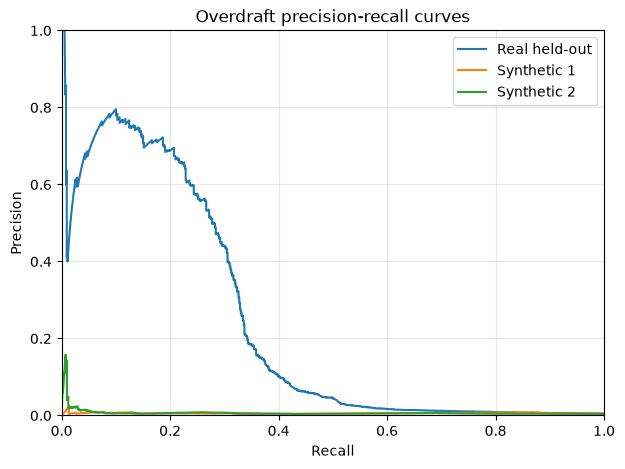

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, (y_true, probabilities) in evaluation_results.items():
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    ax.plot(recall, precision, label=name)
ax.set(title="Overdraft precision-recall curves", xlabel="Recall", ylabel="Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Distribution and relationship diagnostics

Run these after the data-loading and model-evaluation cells. The loader aligns both synthetic datasets' categorical codes with real data; rerun the notebook from the top so the model and scores use the corrected alignment. These plots compare marginal feature drift, feature/label relationships, and the real-trained model's score separation.

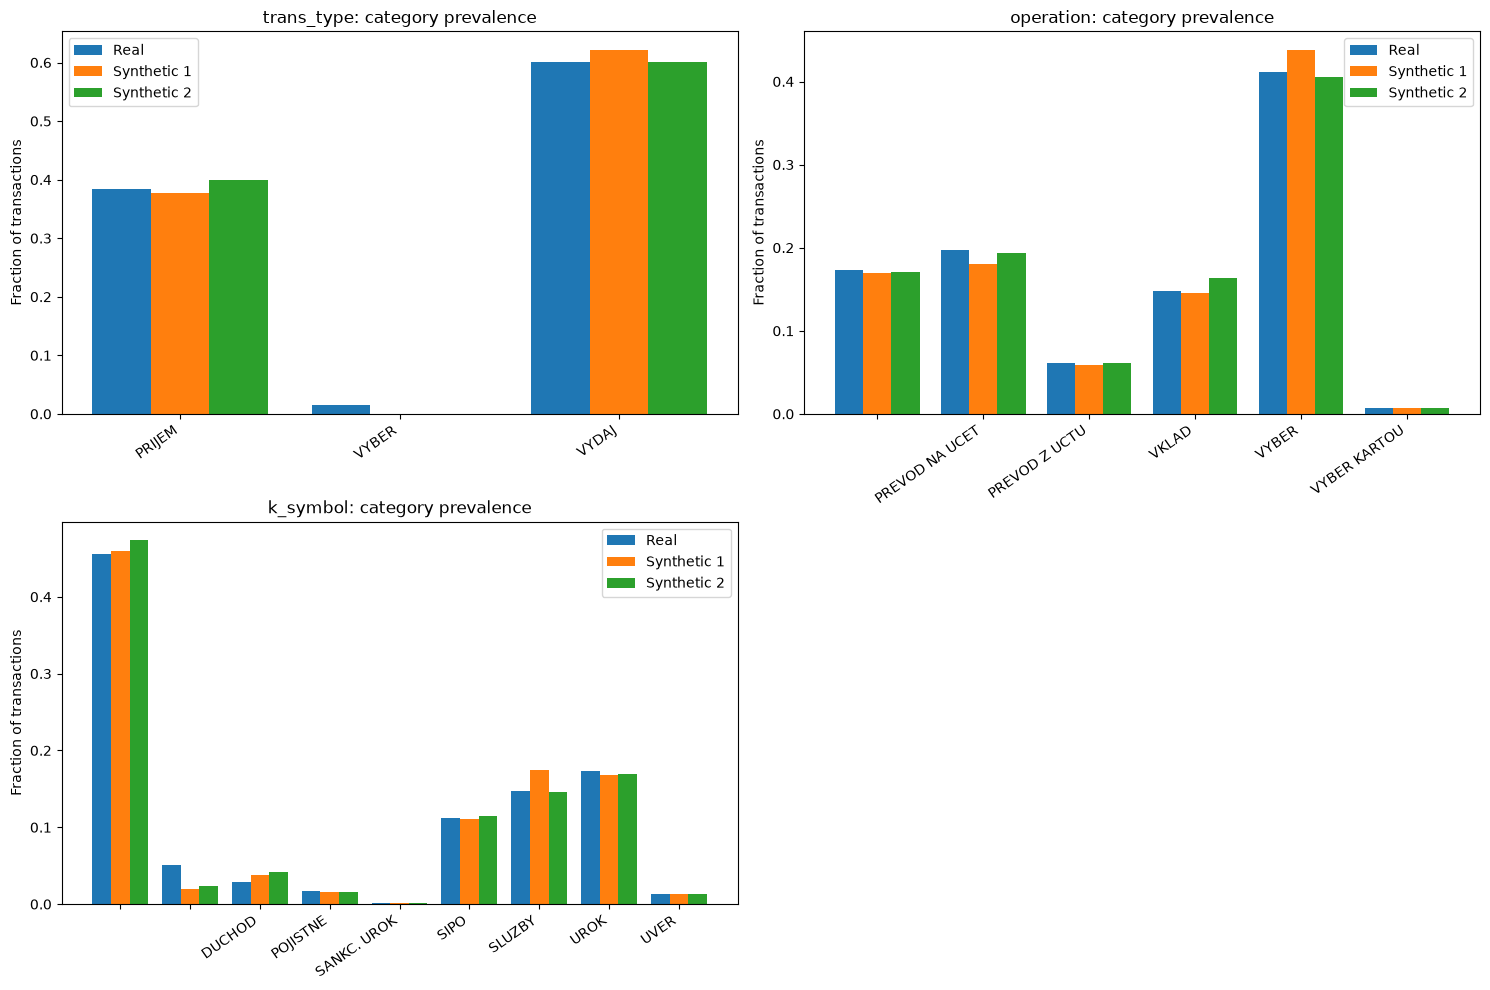

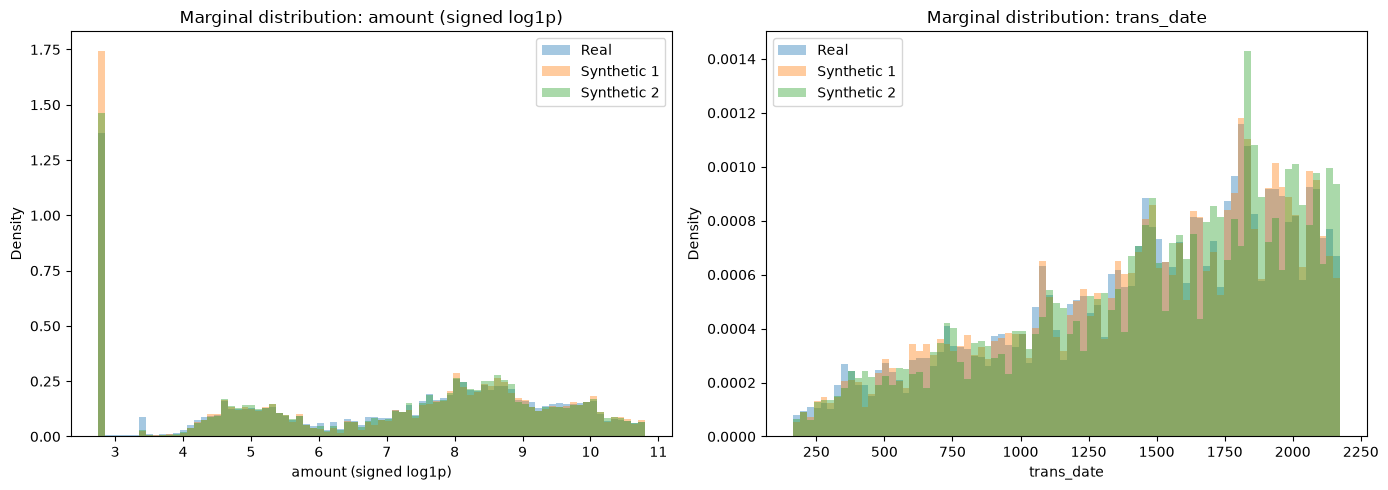

In [6]:
def category_labels_for_plot(data: pd.DataFrame, column: str) -> pd.Series:
    """Map aligned integer category codes to original labels for readable plots."""
    codes = pd.to_numeric(data[column], errors="coerce")
    rounded = codes.round()
    valid = codes.notna() & np.isclose(codes, rounded)
    valid &= rounded.between(0, len(saved_encoders[column].classes_) - 1)
    labels = pd.Series("__unknown__", index=data.index, dtype="object")
    if valid.any():
        labels.loc[valid] = saved_encoders[column].inverse_transform(
            rounded.loc[valid].astype("int64"),
        )
    return labels

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, column in zip(axes.flat, CATEGORICAL_FEATURES, strict=False):
    real_labels = category_labels_for_plot(real, column)
    shares = {"Real": real_labels.value_counts(normalize=True)}
    shares.update(
        {name: category_labels_for_plot(data, column).value_counts(normalize=True)
         for name, data in synthetic_datasets.items()},
    )
    categories = sorted(set().union(*(share.index for share in shares.values())))
    x = np.arange(len(categories))
    width = 0.8 / len(shares)
    for dataset_index, (dataset_name, share) in enumerate(shares.items()):
        offset = (dataset_index - (len(shares) - 1) / 2) * width
        ax.bar(
            x + offset,
            [share.get(category, 0) for category in categories],
            width,
            label=dataset_name,
        )
    ax.set(title=f"{column}: category prevalence", ylabel="Fraction of transactions")
    ax.set_xticks(x, categories, rotation=35, ha="right")
    ax.legend()
axes.flat[-1].set_visible(False)
fig.tight_layout()
plt.show()

def signed_log1p(values: pd.Series) -> np.ndarray:
    """Compress long-tailed values while preserving sign."""
    numeric = pd.to_numeric(values, errors="coerce").to_numpy(dtype=float)
    return np.sign(numeric) * np.log1p(np.abs(numeric))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
numeric_plot_data = [
    ("amount (signed log1p)", lambda data: signed_log1p(data["amount"])),
    ("trans_date", lambda data: data["trans_date"].to_numpy()),
]
for ax, (label, get_values) in zip(axes, numeric_plot_data, strict=False):
    dataset_values = {"Real": get_values(real)}
    dataset_values.update({name: get_values(data) for name, data in synthetic_datasets.items()})
    combined = np.concatenate(
        [values[np.isfinite(values)] for values in dataset_values.values()],
    )
    low, high = np.quantile(combined, [0.005, 0.995])
    bins = np.linspace(low, high, 81)
    for dataset_name, values in dataset_values.items():
        ax.hist(values, bins=bins, density=True, alpha=0.4, label=dataset_name)
    ax.set(title=f"Marginal distribution: {label}", xlabel=label, ylabel="Density")
    ax.legend()
fig.tight_layout()
plt.show()

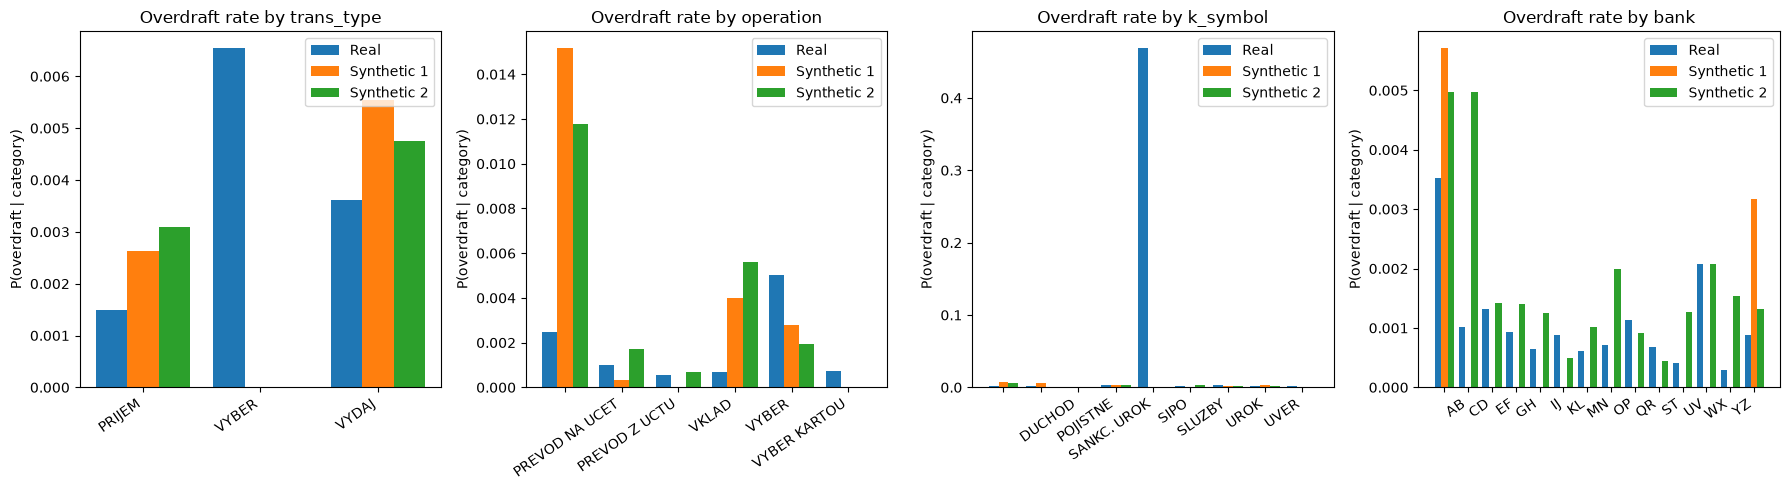

Overdraft rates and support by trans_type:


,dataset,category,transactions,overdrafts,overdraft_rate
0,Real,PRIJEM,405083,601,0.001484
1,Synthetic 1,PRIJEM,6462,17,0.002631
2,Synthetic 2,PRIJEM,39392,122,0.003097
3,Real,VYBER,16666,109,0.006540
4,Synthetic 1,VYBER,1,0,0.000000
5,Synthetic 2,VYBER,12,0,0.000000
6,Real,VYDAJ,634571,2289,0.003607
7,Synthetic 1,VYDAJ,10643,59,0.005544
8,Synthetic 2,VYDAJ,59249,282,0.004760


Overdraft rates and support by operation:


,dataset,category,transactions,overdrafts,overdraft_rate
0,Real,,183114,456,0.002490
1,Synthetic 1,,2902,44,0.015162
2,Synthetic 2,,16892,199,0.011781
3,Real,PREVOD NA UCET,208283,208,0.000999
4,Synthetic 1,PREVOD NA UCET,3083,1,0.000324
5,Synthetic 2,PREVOD NA UCET,19075,33,0.001730
6,Real,PREVOD Z UCTU,65226,36,0.000552
7,Synthetic 1,PREVOD Z UCTU,1011,0,0.000000
8,Synthetic 2,PREVOD Z UCTU,5989,4,0.000668
9,Real,VKLAD,156743,109,0.000695


Overdraft rates and support by k_symbol:


,dataset,category,transactions,overdrafts,overdraft_rate
0,Real,,481881,939,0.001949
1,Synthetic 1,,7860,56,0.007125
2,Synthetic 2,,46782,302,0.006455
3,Real,,53433,110,0.002059
4,Synthetic 1,,334,2,0.005988
5,Synthetic 2,,2336,2,0.000856
6,Real,DUCHOD,30338,0,0.000000
7,Synthetic 1,DUCHOD,657,0,0.000000
8,Synthetic 2,DUCHOD,4140,2,0.000483
9,Real,POJISTNE,18500,54,0.002919


Overdraft rates and support by bank:


,dataset,category,transactions,overdrafts,overdraft_rate
0,Real,,782812,2755,0.003519
1,Synthetic 1,,13139,75,0.005708
2,Synthetic 2,,74395,370,0.004973
3,Real,AB,21720,22,0.001013
4,Synthetic 1,AB,192,0,0.000000
5,Synthetic 2,AB,1006,5,0.004970
6,Real,CD,19597,26,0.001327
7,Synthetic 1,CD,337,0,0.000000
8,Synthetic 2,CD,2119,3,0.001416
9,Real,EF,21293,20,0.000939


In [7]:
categorical_rate_tables = {}
fig, axes = plt.subplots(1, len(CATEGORICAL_FEATURES), figsize=(18, 5))
for ax, column in zip(axes, CATEGORICAL_FEATURES, strict=False):
    records = []
    datasets_for_rates = {"Real": real, **synthetic_datasets}
    for dataset_name, data in datasets_for_rates.items():
        group_data = pd.DataFrame(
            {"category": category_labels_for_plot(data, column), TARGET: data[TARGET]},
        )
        grouped = group_data.groupby("category", observed=True)[TARGET].agg(["size", "sum", "mean"])
        for category, row in grouped.iterrows():
            records.append(
                {
                    "dataset": dataset_name,
                    "category": category,
                    "transactions": int(row["size"]),
                    "overdrafts": int(row["sum"]),
                    "overdraft_rate": float(row["mean"]),
                },
            )
    rates = pd.DataFrame(records)
    categorical_rate_tables[column] = rates
    categories = sorted(rates["category"].unique())
    x = np.arange(len(categories))
    width = 0.8 / len(datasets_for_rates)
    for dataset_index, dataset_name in enumerate(datasets_for_rates):
        offset = (dataset_index - (len(datasets_for_rates) - 1) / 2) * width
        subset = rates[rates["dataset"] == dataset_name].set_index("category")
        ax.bar(
            x + offset,
            [subset["overdraft_rate"].get(category, 0) for category in categories],
            width,
            label=dataset_name,
        )
    ax.set(title=f"Overdraft rate by {column}", ylabel="P(overdraft | category)")
    ax.set_xticks(x, categories, rotation=35, ha="right")
    ax.legend()
fig.tight_layout()
plt.show()

for column, rates in categorical_rate_tables.items():
    print(f"Overdraft rates and support by {column}:")
    display(rates.sort_values(["category", "dataset"]).reset_index(drop=True))

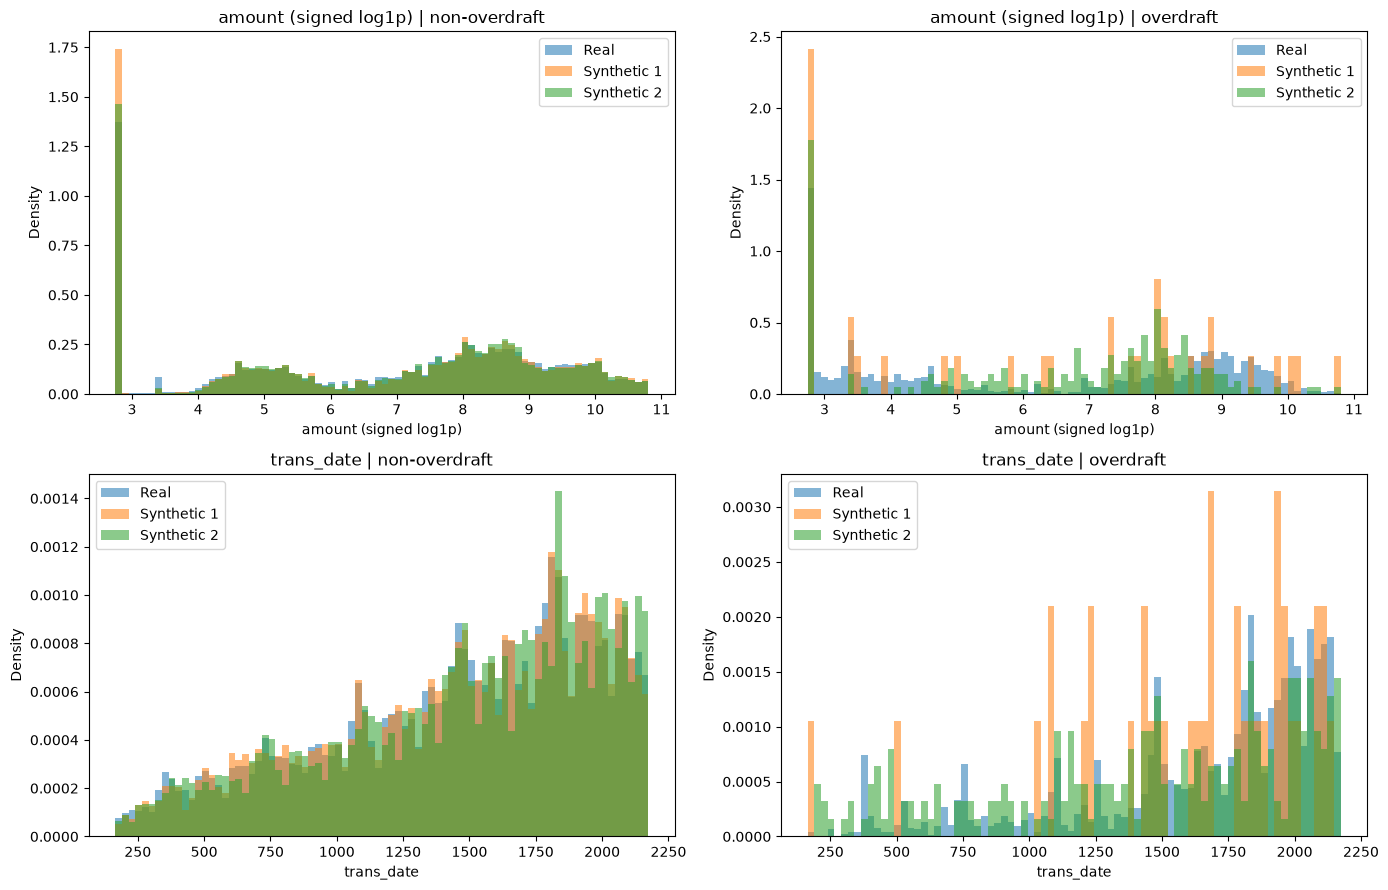

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (feature, transform, label) in enumerate(
    [
        ("amount", signed_log1p, "amount (signed log1p)"),
        ("trans_date", lambda values: pd.to_numeric(values, errors="coerce").to_numpy(dtype=float), "trans_date"),
    ],
):
    datasets_for_comparison = {"Real": real, **synthetic_datasets}
    class_frames = [
        data.loc[data[TARGET] == target_value, feature]
        for target_value in [0, 1]
        for data in datasets_for_comparison.values()
    ]
    transformed = [transform(values) for values in class_frames]
    finite_values = np.concatenate([values[np.isfinite(values)] for values in transformed])
    low, high = np.quantile(finite_values, [0.005, 0.995])
    bins = np.linspace(low, high, 81)
    for col, target_value in enumerate([0, 1]):
        ax = axes[row, col]
        for dataset_name, data in datasets_for_comparison.items():
            values = transform(data.loc[data[TARGET] == target_value, feature])
            ax.hist(values, bins=bins, density=True, alpha=0.55, label=dataset_name)
        ax.set(
            title=f"{label} | {'overdraft' if target_value else 'non-overdraft'}",
            xlabel=label,
            ylabel="Density",
        )
        ax.legend()
fig.tight_layout()
plt.show()

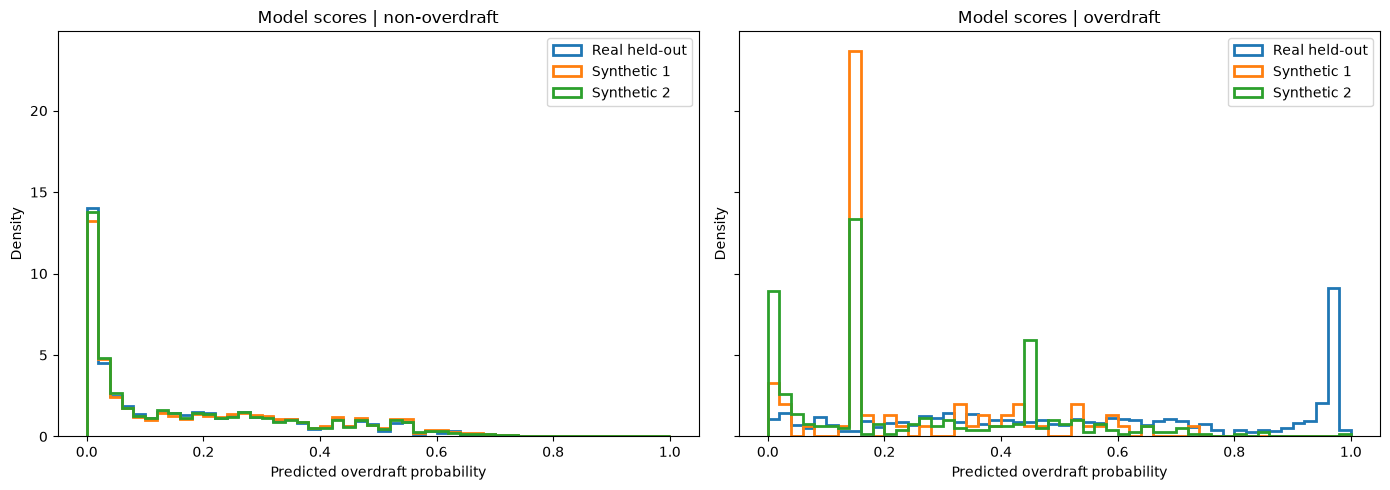

Score separation by dataset and true label:


,dataset,true_label,rows,mean_score,median_score,90th_percentile
0,Real held-out,non-overdraft,210065,0.177271,0.114564,0.467647
1,Real held-out,overdraft,739,0.559007,0.554680,0.972186
2,Synthetic 1,non-overdraft,17030,0.190721,0.128857,0.496690
3,Synthetic 1,overdraft,76,0.240362,0.147174,0.533275
4,Synthetic 2,non-overdraft,98249,0.179151,0.114518,0.473440
5,Synthetic 2,overdraft,404,0.238375,0.146435,0.520145


In [9]:
score_frames = {
    dataset_name: (data[TARGET].to_numpy(), model.predict_proba(data[FEATURES])[:, 1])
    for dataset_name, data in {"Real held-out": real_test, **synthetic_datasets}.items()
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
score_bins = np.linspace(0, 1, 51)
for ax, target_value in zip(axes, [0, 1], strict=False):
    for dataset_name, (labels, probabilities) in score_frames.items():
        scores = probabilities[labels == target_value]
        ax.hist(scores, bins=score_bins, density=True, histtype="step", linewidth=2, label=dataset_name)
    ax.set(
        title=f"Model scores | {'overdraft' if target_value else 'non-overdraft'}",
        xlabel="Predicted overdraft probability",
        ylabel="Density",
    )
    ax.legend()
fig.tight_layout()
plt.show()

print("Score separation by dataset and true label:")
score_summary = []
for dataset_name, (labels, probabilities) in score_frames.items():
    for target_value, target_name in [(0, "non-overdraft"), (1, "overdraft")]:
        scores = probabilities[labels == target_value]
        score_summary.append(
            {
                "dataset": dataset_name,
                "true_label": target_name,
                "rows": len(scores),
                "mean_score": float(scores.mean()),
                "median_score": float(np.median(scores)),
                "90th_percentile": float(np.quantile(scores, 0.9)),
            },
        )
display(pd.DataFrame(score_summary))

## Interpretation and limitations

- Compare synthetic average precision and recall with the real account-held-out results; a large gap indicates transfer/domain shift, not necessarily a failure of the real-data model.
- Compare overdraft prevalences first. A synthetic label rate that differs from real data changes precision and average precision even if ranking quality is similar.
- The real and synthetic overdraft labels are both derived from `balance < 0`; `balance` is deliberately absent from `FEATURES`, so the target cannot be trivially read from the predictors.
- Inputs use the transaction table only. The supplied candidate table notes that richer account/client/district context can help, but adding joins and historical aggregates requires leakage-safe temporal feature engineering and aligned synthetic parent-child keys, which this first experiment does not claim to provide.
- This is a baseline experiment. If operational decisions require a different precision/recall trade-off, choose a threshold using a real validation partition, then freeze it before evaluating any test or synthetic set.

In [1]:
from overdraft_transfer_evaluator import (
    OverdraftTransferEvaluator,
)
from pathlib import Path
import pandas as pd

def find_project_root(start: Path | None = None) -> Path:
    """Find the repository root from the current directory or notebook path."""
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml in the current directory or its parents.")

ROOT = find_project_root()

evaluator = OverdraftTransferEvaluator(
    ROOT / "implementations/tabular_data/multi_table/data/berka2/trans.csv",
    real_data_config={"trans_sample_size": 100_000},
)

evaluator.evaluate_synthetic(
    ROOT / "implementations/tabular_data/multi_table/results2/"
    "ClavaDDPM_notebook/trans/synthetic_final/trans_synthetic.csv",
    name="sample=100k, iterations=5000",
    config={"trans_sample_size": 100_000, "iterations": 5_000},
)

metrics = pd.concat(
    [
        pd.DataFrame([evaluator.real_test_metrics], index=["Real held-out"]),
        evaluator.get_metrics(),
    ]
)

metrics

,rows,overdrafts,overdraft_prevalence,average_precision,roc_auc,precision,recall,f1,threshold,clavaddpm_config,real_data_config
Real held-out,20188,54,0.002675,0.136509,0.824770,0.025033,0.351852,0.046740,0.5,NaN,NaN
"sample=100k, iterations=5000",98653,404,0.004095,0.017194,0.671702,0.008414,0.066832,0.014946,0.5,"{""iterations"": 5000, ""trans_sample_size"": 100000}","{""trans_sample_size"": 100000}"


In [2]:
engineered_features = [
    "calendar_weekday_sin",
    "calendar_weekday_cos",
    "calendar_month_sin",
    "calendar_month_cos",
    "history_days_since_previous_active_day",
    "history_prior_7d_transaction_count",
    "history_prior_7d_inflow",
    "history_prior_7d_outflow",
    "history_prior_7d_net_flow",
    "history_prior_30d_transaction_count",
    "history_prior_30d_inflow",
    "history_prior_30d_outflow",
    "history_prior_30d_net_flow",
    "history_prior_30d_mean_amount",
    "history_prior_30d_overdraft_count",
    "history_prior_30d_overdraft_rate",
    "amount_to_prior_30d_mean",
]

evaluator_fe = OverdraftTransferEvaluator(
    ROOT / "implementations/tabular_data/multi_table/data/berka_feature_engineered/trans.csv",
    additional_features=engineered_features,
    real_data_config={"trans_sample_size": 100_000},
)

evaluator_fe.evaluate_synthetic(
    ROOT / "implementations/tabular_data/multi_table/results/"
    "feature_100k_run1/ClavaDDPM_experiment/trans/synthetic_final/trans_synthetic.csv",
    name="sample=100k, iterations=5000",
    config={"trans_sample_size": 100_000, "iterations": 5_000},
)

metrics_fe = pd.concat(
    [
        pd.DataFrame([evaluator_fe.real_test_metrics], index=["Real held-out"]),
        evaluator_fe.get_metrics(),
    ]
)

metrics_fe

,rows,overdrafts,overdraft_prevalence,average_precision,roc_auc,precision,recall,f1,threshold,clavaddpm_config,real_data_config
Real held-out,210804,739,0.003506,0.769318,0.991458,0.492788,0.832206,0.619024,0.5,NaN,NaN
"sample=100k, iterations=5000",104278,4208,0.040354,0.552021,0.889856,0.921016,0.473859,0.625765,0.5,"{""iterations"": 5000, ""trans_sample_size"": 100000}","{""trans_sample_size"": 100000}"


In [3]:
engineered_features_no_history = [
    "calendar_weekday_sin",
    "calendar_weekday_cos",
    "calendar_month_sin",
    "calendar_month_cos",
    "history_days_since_previous_active_day",
    "history_prior_7d_transaction_count",
    "history_prior_7d_inflow",
    "history_prior_7d_outflow",
    "history_prior_7d_net_flow",
    "history_prior_30d_transaction_count",
    "history_prior_30d_inflow",
    "history_prior_30d_outflow",
    "history_prior_30d_net_flow",
    "history_prior_30d_mean_amount",
    # "history_prior_30d_overdraft_count",
    # "history_prior_30d_overdraft_rate",
    "amount_to_prior_30d_mean",
]

evaluator_fe_no_history = OverdraftTransferEvaluator(
    ROOT / "implementations/tabular_data/multi_table/data/berka_feature_engineered/trans.csv",
    additional_features=engineered_features_no_history,
    real_data_config={"trans_sample_size": 100_000},
)

evaluator_fe_no_history.evaluate_synthetic(
    ROOT / "implementations/tabular_data/multi_table/results/"
    "feature_100k_run1/ClavaDDPM_experiment/trans/synthetic_final/trans_synthetic.csv",
    name="sample=100k, iterations=5000",
    config={"trans_sample_size": 100_000, "iterations": 5_000},
)

metrics_fe_no_history = pd.concat(
    [
        pd.DataFrame([evaluator_fe_no_history.real_test_metrics], index=["Real held-out"]),
        evaluator_fe_no_history.get_metrics(),
    ]
)

metrics_fe_no_history

,rows,overdrafts,overdraft_prevalence,average_precision,roc_auc,precision,recall,f1,threshold,clavaddpm_config,real_data_config
Real held-out,210804,739,0.003506,0.354438,0.958817,0.164979,0.595399,0.258368,0.5,NaN,NaN
"sample=100k, iterations=5000",104278,4208,0.040354,0.143174,0.803666,0.060976,0.014259,0.023112,0.5,"{""iterations"": 5000, ""trans_sample_size"": 100000}","{""trans_sample_size"": 100000}"
